# TP02: logistic regression, from NumPy to PyTorch

**MSA-DATB09-03 · Neural Networks & Deep Learning Foundations · Session 2 / 8** · Guillaume Saint-Cirgue

*Estimated time: 80 minutes*

In the course we replaced the step of the perceptron by the sigmoid and derived everything by hand: the
score $z = w^\top x + b$, the probability $a = \sigma(z)$, the log loss
$J = -\frac{1}{m}\sum [y \log a + (1 - y)\log(1 - a)]$ and its gradient $dw = \frac{1}{m}X^\top(A - y)$,
$db = \frac{1}{m}\sum(a - y)$. In this notebook you code it yourself, first with NumPy (so that nothing is
hidden), then with PyTorch (so that you see what the library does for you).

**How it works.** Each exercise is a cell with a zone to complete:

```python
### START CODE HERE ###

### END CODE HERE ###
```

Write your code between the two markers, then run the cell: the `assert` lines below the zone check your
answer and print `Exercise validated!` when it is correct. If an assert fails, read its message: it tells
you what to look at.

**Run it** on Google Colab (File > Upload notebook) or locally with the course `requirements.txt`.

## Imports

- `numpy`: arrays and vectorised maths, we write the model with it in Parts A and B.
- `matplotlib`: plots (loss curve, decision boundary).
- `torch`: PyTorch, used in Part C. `torch.nn` contains the layers and the losses.
- `sklearn.datasets`: `make_blobs` and `make_moons` generate our 2-D toy datasets.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.datasets import make_blobs, make_moons

FAST_RUN = os.environ.get("FAST_RUN", "0") == "1"   # True: quick check run (everything is fast here anyway)
np.random.seed(0)
torch.manual_seed(0)

## Helper functions (run this cell, no need to modify it)

`plot_boundary(X, y, predict_proba)` colours the plane with the predicted probability $P(y = 1 \mid x)$ and
draws the decision boundary (where the probability is 0.5). `predict_proba` is any function that takes an
array of points of shape `(k, 2)` and returns their probabilities, shape `(k,)`.

In [2]:
def plot_boundary(X, y, predict_proba, title=""):
    x1, x2 = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200))
    grid = np.c_[x1.ravel(), x2.ravel()]
    P = predict_proba(grid).reshape(x1.shape)
    plt.figure(figsize=(5.5, 4.5))
    plt.contourf(x1, x2, P, levels=np.linspace(0, 1, 11), cmap="coolwarm_r", alpha=0.3)
    plt.contour(x1, x2, P, levels=[0.5], colors="k")
    plt.scatter(X[y == 1, 0], X[y == 1, 1], c="#4338ca", s=20, label="class 1")
    plt.scatter(X[y == 0, 0], X[y == 0, 1], c="#d97706", s=20, marker="s", label="class 0")
    plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.title(title); plt.legend()
    plt.show()

## The dataset: toxic plants

Each plant is described by 2 measurements (for example the width and the length of its leaves, in some
unit) and a label: 1 if it is toxic, 0 otherwise. `make_blobs` generates 100 such plants in two clusters:

- `n_samples=100`: 100 examples; `n_features=2`: 2 features; `centers=2`: 2 clusters (the 2 classes);
- `random_state=0`: everybody gets the same data.

`X` has shape `(100, 2)` (one plant per row) and `y` has shape `(100,)` (0 or 1).

X: (100, 2)  y: (100,)  toxic plants: 50


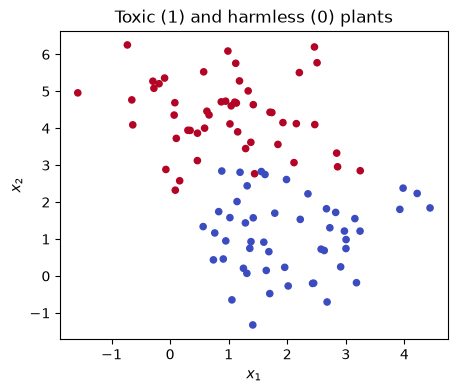

In [3]:
X, y = make_blobs(n_samples=100, n_features=2, centers=2, random_state=0)
print("X:", X.shape, " y:", y.shape, " toxic plants:", y.sum())
plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm_r", s=20)
plt.xlabel("$x_1$"); plt.ylabel("$x_2$"); plt.title("Toxic (1) and harmless (0) plants")
plt.show()

# Part A: logistic regression in NumPy

### Exercise 1: the sigmoid

Implement $\sigma(z) = \dfrac{1}{1 + e^{-z}}$. It must work on a number **and** on an array (element by
element), so use `np.exp`, not `math.exp`.

In [4]:
def sigmoid(z):
    ### START CODE HERE ###
    a = 1 / (1 + np.exp(-z))
    ### END CODE HERE ###
    return a


assert sigmoid(0) == 0.5, "sigmoid(0) should be exactly 0.5"
assert np.isclose(sigmoid(2), 0.8808, atol=1e-4), "sigmoid(2) should be about 0.881 (exercise 1 of the course)"
assert np.isclose(sigmoid(2) + sigmoid(-2), 1), "sigmoid(-z) should equal 1 - sigmoid(z)"
assert sigmoid(np.zeros(4)).shape == (4,), "sigmoid must work element by element on an array"
print("Exercise validated!")

Exercise validated!


### Exercise 2: initialisation

Write `initialisation(n)` that returns random parameters: `w` of shape `(n,)` drawn from a standard normal
distribution, and a number `b` drawn the same way.

- `np.random.randn(n)` returns an array of `n` numbers drawn from $\mathcal{N}(0, 1)$;
  `np.random.randn()` (no argument) returns a single number.

In [5]:
def initialisation(n):
    ### START CODE HERE ###
    w, b = np.random.randn(n), np.random.randn()
    ### END CODE HERE ###
    return w, b


np.random.seed(0)
w, b = initialisation(2)
assert w.shape == (2,), f"w should have shape (2,), not {np.shape(w)}"
assert np.isscalar(b), "b should be a single number"
assert np.allclose(w, [1.7641, 0.4002], atol=1e-4), "draw w first with np.random.randn(n), then b"
print("Exercise validated!")

Exercise validated!


### Exercise 3: the model (forward pass)

Write `model(X, w, b)` that returns the vector `A` of the $m$ probabilities $a^{(i)} = \sigma(w^\top x^{(i)} + b)$,
in one line and without a Python loop.

- `X @ w` multiplies every row of `X` (shape `(m, n)`) by `w` (shape `(n,)`): the result has shape `(m,)`.

In [6]:
def model(X, w, b):
    ### START CODE HERE ###
    A = sigmoid(X @ w + b)
    ### END CODE HERE ###
    return A


A_test = model(np.array([[1.0, 3.0], [0.0, 0.0]]), np.array([2.0, -1.0]), -1.0)
assert A_test.shape == (2,), "one probability per row of X"
assert np.isclose(A_test[0], 0.1192, atol=1e-4), "exercise 1 of the course: z = -2, a = 0.119"
assert np.isclose(A_test[1], sigmoid(-1.0)), "for x = (0, 0), z = b"
print("Exercise validated!")

Exercise validated!


### Exercise 4: the log loss

Write `log_loss(A, y)`:

$$ J = -\frac{1}{m}\sum_{i=1}^{m}\left[ y^{(i)} \log a^{(i)} + (1 - y^{(i)}) \log(1 - a^{(i)}) \right] $$

- `np.log` is the natural logarithm, element by element; `np.mean` averages an array.
- If a probability is exactly 0 or 1, `np.log(0)` gives `-inf`. Add a tiny `eps = 1e-15` inside each log:
  `np.log(A + eps)` and `np.log(1 - A + eps)`.

In [7]:
def log_loss(A, y, eps=1e-15):
    ### START CODE HERE ###
    J = -np.mean(y * np.log(A + eps) + (1 - y) * np.log(1 - A + eps))
    ### END CODE HERE ###
    return J


J_ex2 = log_loss(np.array([0.9, 0.5, 0.1]), np.array([1, 1, 1]))
assert np.isclose(J_ex2, 1.0337, atol=1e-4), f"exercise 2 of the course gives J = 1.034, not {J_ex2}"
assert np.isclose(log_loss(np.array([0.5, 0.5]), np.array([1, 0])), np.log(2)), "a = 0.5 everywhere gives log 2"
assert np.isfinite(log_loss(np.array([0.0, 1.0]), np.array([1, 0]))), "use eps so that log(0) never happens"
print("Exercise validated!")

Exercise validated!


### Exercise 5: the gradients

Write `gradients(A, X, y)` that returns

$$ dw = \frac{1}{m}\, X^\top (A - y) \quad \text{(shape } (n,)\text{)}, \qquad db = \frac{1}{m}\sum_{i=1}^{m} (a^{(i)} - y^{(i)}) $$

- `X.T` is the transpose of `X`, shape `(n, m)`; `X.T @ (A - y)` has shape `(n,)`.
- `len(y)` is $m$.

The test reproduces exercise 3 of the course (two examples, $w = 0$, $b = 0$).

In [8]:
def gradients(A, X, y):
    ### START CODE HERE ###
    dw = X.T @ (A - y) / len(y)
    db = np.mean(A - y)
    ### END CODE HERE ###
    return dw, db


X_ex3, y_ex3 = np.array([[2.0, 1.0], [0.0, 2.0]]), np.array([1.0, 0.0])
dw, db = gradients(model(X_ex3, np.zeros(2), 0.0), X_ex3, y_ex3)
assert np.shape(dw) == (2,), "dw must have the shape of w"
assert np.allclose(dw, [-0.5, 0.25]) and np.isclose(db, 0), f"exercise 3: dw = (-0.5, 0.25), db = 0; got {dw}, {db}"
print("Exercise validated!")

Exercise validated!


### Exercise 6: the update

Write `update(dw, db, w, b, eta)` that does one step of gradient descent and returns the new `w, b`:
$w \leftarrow w - \eta\, dw$, $b \leftarrow b - \eta\, db$. Then check exercise 3 of the course: after one
step with $\eta = 2$, $w = (1, -0.5)$ and the cost drops from 0.693 to 0.257.

In [23]:
def update(dw, db, w, b, eta):
    ### START CODE HERE ###
    w = w - eta * dw
    b = b - eta * db
    ### END CODE HERE ###
    return w, b


w1, b1 = update(dw, db, np.zeros(2), 0.0, eta=2)
assert np.allclose(w1, [1, -0.5]) and np.isclose(b1, 0), f"expected w = (1, -0.5), b = 0, got {w1}, {b1}"
J1 = log_loss(model(X_ex3, w1, b1), y_ex3)
assert np.isclose(J1, 0.2573, atol=1e-4), f"the new cost should be 0.257, got {J1}"
print("Exercise validated! The cost went from 0.693 to", round(J1, 3))

Exercise validated! The cost went from 0.693 to 0.257


### Exercise 7: the training loop

Put everything together in `logistic_regression(X, y, eta, n_iter)`:

1. initialise `w, b` with `initialisation`;
2. repeat `n_iter` times: forward pass (`model`), store the loss in the list `losses`, compute the
   gradients, update the parameters;
3. return `w, b, losses`.

loss: first 2.229  last 0.148
Exercise validated!


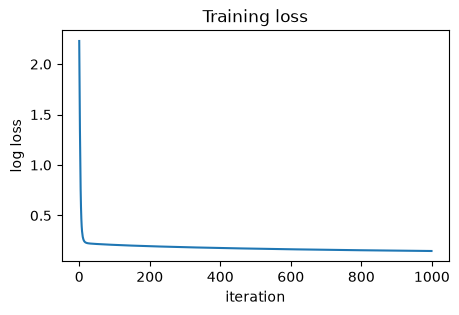

In [24]:
def logistic_regression(X, y, eta=0.1, n_iter=1000):
    ### START CODE HERE ###
    w, b = initialisation(X.shape[1])
    losses = []
    for _ in range(n_iter):
        A = model(X, w, b)
        losses.append(log_loss(A, y))
        dw, db = gradients(A, X, y)
        w, b = update(dw, db, w, b, eta)
    ### END CODE HERE ###
    return w, b, losses


np.random.seed(0)
w, b, losses = logistic_regression(X, y, eta=0.1, n_iter=1000)
print("loss: first", round(losses[0], 3), " last", round(losses[-1], 3))
assert len(losses) == 1000, "one loss per iteration"
assert np.all(np.diff(losses) < 0), "with this learning rate the loss must decrease at every iteration"
assert losses[-1] < 0.2, "the final loss should be below 0.2"
print("Exercise validated!")

plt.figure(figsize=(5, 3))
plt.plot(losses)
plt.xlabel("iteration"); plt.ylabel("log loss"); plt.title("Training loss")
plt.show()

### Exercise 8: predictions and accuracy

Write `predict(X, w, b)` that returns the predicted classes (1 if $a \ge 0.5$, else 0, as integers), then
compute the training accuracy `acc` (the fraction of correct predictions).

- `(A >= 0.5).astype(int)` turns probabilities into 0/1; `np.mean(y_pred == y)` is the accuracy.

training accuracy: 0.93
Exercise validated!


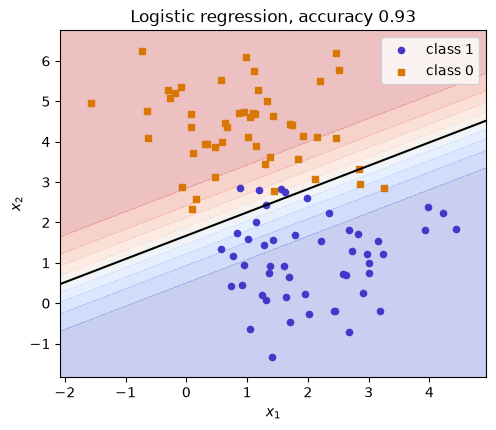

In [34]:
def predict(X, w, b):
    ### START CODE HERE ###
    y_pred = (model(X, w, b) >= 0.5).astype(int)
    ### END CODE HERE ###
    return y_pred


### START CODE HERE ###
acc = np.mean(predict(X, w, b) == y)
### END CODE HERE ###

print("training accuracy:", acc)
assert predict(X, w, b).shape == (100,), "one predicted class per plant"
assert acc > 0.9, "the accuracy should be above 0.9"
print("Exercise validated!")
plot_boundary(X, y, lambda P: model(P, w, b), f"Logistic regression, accuracy {acc:.2f}")

**What we see.** The loss drops quickly, then slowly. The boundary (black) is a straight line, exactly the
line $w^\top x + b = 0$, but unlike the perceptron each point now has a probability: the colour fades near
the line, where the model is unsure.

### Exercise 9: a new plant

A new plant has measurements $x = (2, 1)$. Compute `p_new`, the probability that it is toxic, with your
trained `w, b` (careful: `model` expects a 2-D array of shape `(1, 2)`; take element `[0]` of the result).

In [26]:
x_new = np.array([[2.0, 1.0]])

### START CODE HERE ###
p_new = model(x_new, w, b)[0]
### END CODE HERE ###

print("P(toxic) =", round(p_new, 3))
assert 0.9 < p_new < 1, "this plant is deep in the toxic cluster: the probability should be above 0.9"
print("Exercise validated!")

P(toxic) = 0.969
Exercise validated!


# Part B: check the gradient numerically

A gradient formula derived by hand can be wrong. The classic test: compare it with a **finite difference**.
For one parameter $w_j$, with a tiny $h$:

$$ \frac{\partial J}{\partial w_j} \approx \frac{J(w_j + h) - J(w_j - h)}{2h} $$

### Exercise 10: the numerical gradient

Write `numerical_gradient(X, y, w, b, h)` that returns an array of shape `(n,)` with the finite-difference
estimate for every $w_j$ (a loop over `j` is fine). For each `j`, copy `w` (`w_plus = w.copy()`), add `h` to
component `j`, compute the loss; do the same with `-h`.

In [27]:
def numerical_gradient(X, y, w, b, h=1e-5):
    ### START CODE HERE ###
    grad = np.zeros_like(w)
    for j in range(len(w)):
        w_plus, w_minus = w.copy(), w.copy()
        w_plus[j] += h
        w_minus[j] -= h
        grad[j] = (log_loss(model(X, w_plus, b), y) - log_loss(model(X, w_minus, b), y)) / (2 * h)
    ### END CODE HERE ###
    return grad


w_check, b_check = np.array([0.3, -0.2]), 0.1
num = numerical_gradient(X, y, w_check, b_check)
assert np.shape(num) == (2,), "one estimate per weight"
assert np.allclose(w_check, [0.3, -0.2]), "do not modify w itself: work on copies"
print("numerical:", num)
print("Exercise validated!")

numerical: [-0.13468459  0.57845834]
Exercise validated!


### Exercise 11: compare with the formula

Compute `analytic`, the `dw` of your function `gradients` at the same point, and the **relative error**

$$ \text{rel\_error} = \frac{\lVert dw_{\text{formula}} - dw_{\text{numerical}} \rVert}{\lVert dw_{\text{formula}} \rVert + \lVert dw_{\text{numerical}} \rVert} $$

- `np.linalg.norm(v)` is the Euclidean norm $\lVert v \rVert$.

In [28]:
### START CODE HERE ###
analytic, _ = gradients(model(X, w_check, b_check), X, y)
rel_error = np.linalg.norm(analytic - num) / (np.linalg.norm(analytic) + np.linalg.norm(num))
### END CODE HERE ###

print("formula:  ", analytic)
print("relative error:", rel_error)
assert rel_error < 1e-7, "the two gradients should agree to better than 1e-7"
print("Exercise validated! The formula (a - y) x is right.")

formula:   [-0.13468459  0.57845834]
relative error: 4.1646559679906265e-11
Exercise validated! The formula (a - y) x is right.


# Part C: the same model in PyTorch

A PyTorch **tensor** is like a NumPy array, with two extras: it can live on a GPU, and it can record the
operations made with it to compute gradients automatically (**autograd**).

### Exercise 12: from NumPy to tensors

Convert the data to tensors of 32-bit floats (the default type of PyTorch layers): `X_t` of shape
`(100, 2)` and `y_t` of shape `(100,)`.

- `torch.tensor(array, dtype=torch.float32)` copies a NumPy array into a new tensor of that type.

In [29]:
### START CODE HERE ###
X_t = torch.tensor(X, dtype=torch.float32)
y_t = torch.tensor(y, dtype=torch.float32)
### END CODE HERE ###

assert X_t.shape == (100, 2) and y_t.shape == (100,), "check the shapes"
assert X_t.dtype == torch.float32 and y_t.dtype == torch.float32, "use dtype=torch.float32 (y too: the loss needs floats)"
print("Exercise validated!")

Exercise validated!


### Exercise 13: autograd computes the gradient for you

Create the parameters as tensors that **require a gradient**, starting from `w_check`, `b_check` of Part B:

- `torch.tensor(values, dtype=torch.float32, requires_grad=True)`: PyTorch will record every operation
  made with this tensor;
- `torch.sigmoid(z)`, `torch.log(t)`, `t.mean()` work like their NumPy versions;
- `loss.backward()` goes back through the recorded operations (chain rule) and stores
  $\partial J / \partial w$ in `w_t.grad` and $\partial J / \partial b$ in `b_t.grad`.

Write the forward pass (`A_t`), the log loss (`loss`, the same formula as in Part A, no `eps` needed here),
then call `loss.backward()`. The asserts compare `w_t.grad` with your NumPy formula.

In [30]:
w_t = torch.tensor(w_check, dtype=torch.float32, requires_grad=True)
b_t = torch.tensor(b_check, dtype=torch.float32, requires_grad=True)

### START CODE HERE ###
A_t = torch.sigmoid(X_t @ w_t + b_t)
loss = -(y_t * torch.log(A_t) + (1 - y_t) * torch.log(1 - A_t)).mean()
loss.backward()
### END CODE HERE ###

print("autograd:", w_t.grad, b_t.grad)
print("NumPy:   ", analytic)
assert w_t.grad is not None, "call loss.backward()"
assert np.allclose(w_t.grad.numpy(), analytic, atol=1e-5), "autograd must give the same dw as the formula"
_, db_check = gradients(model(X, w_check, b_check), X, y)
assert np.isclose(b_t.grad.item(), db_check, atol=1e-5), "autograd must give the same db as the formula"
print("Exercise validated!")

autograd: tensor([-0.1347,  0.5785]) tensor(0.0014)
NumPy:    [-0.13468459  0.57845834]
Exercise validated!


### Exercise 14: gradient descent with autograd

Now train with tensors, still writing the update yourself. Each iteration:

1. forward pass and loss (as above);
2. `loss.backward()` to fill `w_t.grad` and `b_t.grad`;
3. update **inside** `with torch.no_grad():` (we change the parameters, this must not be recorded):
   `w_t -= eta * w_t.grad` and `b_t -= eta * b_t.grad`;
4. reset the gradients with `w_t.grad.zero_()` and `b_t.grad.zero_()`: PyTorch **adds** new gradients to
   the old ones, so without this reset they would accumulate.

We start from the same initial values as the NumPy training of Exercise 7 (seed 0), so the final weights
must be the same.

In [32]:
np.random.seed(0)
w0, b0 = initialisation(2)
w_t = torch.tensor(w0, dtype=torch.float32, requires_grad=True)
b_t = torch.tensor(b0, dtype=torch.float32, requires_grad=True)
eta = 0.1

for i in range(1000):
    ### START CODE HERE ###
    A_t = torch.sigmoid(X_t @ w_t + b_t)
    loss = -(y_t * torch.log(A_t) + (1 - y_t) * torch.log(1 - A_t)).mean()
    loss.backward()
    with torch.no_grad():
        w_t -= eta * w_t.grad
        b_t -= eta * b_t.grad
    w_t.grad.zero_()
    b_t.grad.zero_()
    ### END CODE HERE ###

print("PyTorch:", w_t.detach().numpy(), b_t.item())
print("NumPy:  ", w, b)
assert np.allclose(w_t.detach().numpy(), w, atol=1e-3), "the PyTorch weights should equal the NumPy ones"
assert np.isclose(b_t.item(), b, atol=1e-3), "the PyTorch bias should equal the NumPy one"
print("Exercise validated!")

PyTorch: [ 1.08398   -1.8780154] 3.1417200565338135
NumPy:   [ 1.08397996 -1.87801536] 3.1417198210463697
Exercise validated!


### Exercise 15: the idiomatic PyTorch model

In practice we do not create `w` and `b` by hand. We use three ready-made objects:

- `nn.Linear(2, 1)`: a layer with 2 inputs and 1 output. It holds `weight` (shape `(1, 2)`) and `bias`
  (shape `(1,)`), initialised randomly, and computes `X @ weight.T + bias`: the logits $z$, shape `(m, 1)`.
- `nn.BCEWithLogitsLoss()`: the log loss, but it takes the **logits** $z$ (not the probabilities) and applies
  the sigmoid itself, in a numerically stable way.
- `torch.optim.SGD(params, lr=0.1)`: the optimiser. `model.parameters()` gives it the tensors to update;
  `optimizer.step()` does $w \leftarrow w - \eta\,\nabla J$ for all of them.

Create `model_t`, `loss_fn` and `optimizer`.

In [35]:
torch.manual_seed(0)

### START CODE HERE ###
model_t = nn.Linear(2, 1)
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.SGD(model_t.parameters(), lr=0.1)
### END CODE HERE ###

assert model_t.weight.shape == (1, 2) and model_t.bias.shape == (1,), "nn.Linear(2, 1): 2 inputs, 1 output"
assert isinstance(loss_fn, nn.BCEWithLogitsLoss), "use nn.BCEWithLogitsLoss"
assert optimizer.param_groups[0]["lr"] == 0.1, "learning rate 0.1"
print("Exercise validated!")

Exercise validated!


### Exercise 16: the 5-line training loop

Write the loop body, the 5 lines that you will write in every PyTorch project:

1. `optimizer.zero_grad()`: reset the gradients of all parameters;
2. `z = model_t(X_t).squeeze(1)`: forward pass; `.squeeze(1)` removes the dimension of size 1, so that
   `z` has shape `(100,)` like `y_t`;
3. `loss = loss_fn(z, y_t)`;
4. `loss.backward()`;
5. `optimizer.step()`.

Store each `loss.item()` (the loss as a Python number) in `losses_t`.

In [36]:
losses_t = []
for i in range(1000):
    ### START CODE HERE ###
    optimizer.zero_grad()
    z = model_t(X_t).squeeze(1)
    loss = loss_fn(z, y_t)
    loss.backward()
    optimizer.step()
    losses_t.append(loss.item())
    ### END CODE HERE ###

with torch.no_grad():                                   # no gradient needed to evaluate
    acc_t = ((model_t(X_t).squeeze(1) > 0).float() == y_t).float().mean().item()
assert len(losses_t) == 1000, "store one loss per iteration"
print("final loss:", round(losses_t[-1], 3), " accuracy:", acc_t)
assert losses_t[-1] < losses_t[0], "the loss must decrease"
assert acc_t > 0.9, "same quality as the NumPy model: accuracy above 0.9"
print("Exercise validated!")

final loss: 0.156  accuracy: 0.9200000166893005
Exercise validated!


**What we see.** Positive logit $z > 0$ means $a > 0.5$: that is why we compare `z > 0` for the accuracy.
The final weights differ a little from the NumPy ones (another random start), but the accuracy is the same:
it is the same algorithm, written with library objects.

### Exercise 17: why logits?

Take one example with logit $z = -200$ and label $y = 1$. Compute the loss in two ways:

- `naive`: `-torch.log(torch.sigmoid(z))`;
- `stable`: `loss_fn(z, y)` with `nn.BCEWithLogitsLoss`.

The exact value is $\log(1 + e^{200}) \approx 200$.

In [20]:
z_big, y_one = torch.tensor([-200.0]), torch.tensor([1.0])

### START CODE HERE ###
naive = -torch.log(torch.sigmoid(z_big))
stable = loss_fn(z_big, y_one)
### END CODE HERE ###

print("naive:", naive.item(), " stable:", stable.item())
assert torch.isinf(naive).all(), "in float32, sigmoid(-200) rounds to 0 and -log(0) is infinite"
assert abs(stable.item() - 200) < 1e-3, "BCEWithLogitsLoss gives the right value, 200"
print("Exercise validated!")

naive: inf  stable: 200.0
Exercise validated!


# Part D: the limit

### Exercise 18: logistic regression on the moons

`make_moons` generates two interleaved half circles (`noise=0.1` adds a little noise). Train your NumPy
logistic regression on it (`eta=1.0`, `n_iter=1000`, after `np.random.seed(0)`) and compute the accuracy
`acc_moons`.

accuracy on the moons: 0.885
Exercise validated!


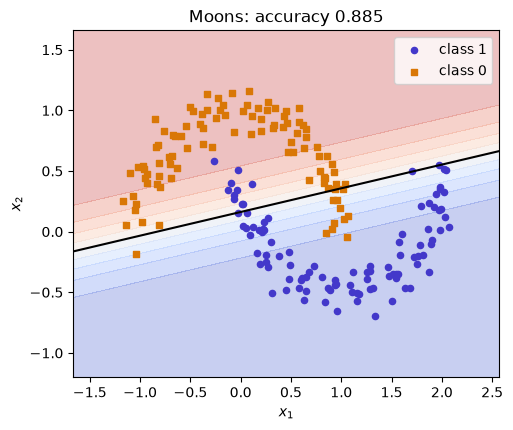

In [37]:
X_m, y_m = make_moons(n_samples=200, noise=0.1, random_state=0)

### START CODE HERE ###
np.random.seed(0)
w_m, b_m, _ = logistic_regression(X_m, y_m, eta=1.0, n_iter=1000)
acc_moons = np.mean(predict(X_m, w_m, b_m) == y_m)
### END CODE HERE ###

print("accuracy on the moons:", acc_moons)
assert 0.8 < acc_moons < 0.92, "a straight line cannot do much better than about 0.88 here"
print("Exercise validated!")
plot_boundary(X_m, y_m, lambda P: model(P, w_m, b_m), f"Moons: accuracy {acc_moons:.3f}")

**What we see.** The model finds the best **line**, and the tips of the moons stay on the wrong side.
Training longer does not help: the limit is the model, not the optimisation. Next session we combine
several neurons, and the boundary will bend.

# Going further

### Exercise 19: the learning rate

Train the NumPy model on the toxic plants with three learning rates, `0.001`, `0.1` and `10`, for 200
iterations each (always after `np.random.seed(0)`, so the start is the same). Store the three loss lists
in the dictionary `curves`, with the learning rate as key. Then look at the plot.

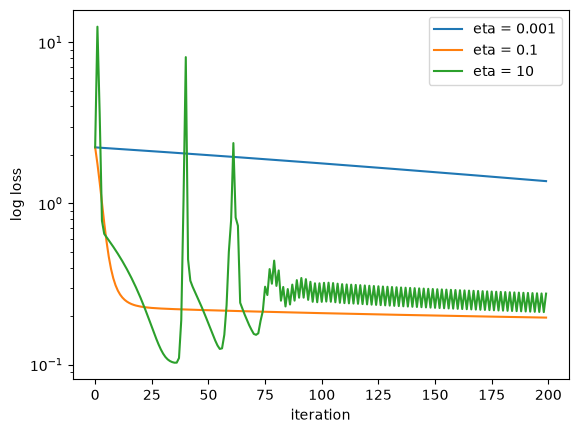

Exercise validated!


In [38]:
curves = {}
### START CODE HERE ###
for eta in [0.001, 0.1, 10]:
    np.random.seed(0)
    _, _, curves[eta] = logistic_regression(X, y, eta=eta, n_iter=200)
### END CODE HERE ###

for eta, L in curves.items():
    plt.plot(L, label=f"eta = {eta}")
plt.yscale("log"); plt.xlabel("iteration"); plt.ylabel("log loss"); plt.legend(); plt.show()
assert set(curves) == {0.001, 0.1, 10}, "one curve per learning rate"
assert curves[0.001][-1] > curves[0.1][-1], "a tiny learning rate is too slow"
assert np.any(np.diff(curves[10]) > 0), "with eta = 10 the loss goes up at some iterations: the steps overshoot"
print("Exercise validated!")

**What we see.** With $\eta = 0.001$ the loss barely moves in 200 iterations. With $\eta = 10$ the steps are
so large that the loss jumps up and down instead of decreasing smoothly. A good learning rate is large
enough to be fast and small enough to be stable: we will tune it in every project.